# Tracking efficiency and SVT hits — 2021 tritrig MC

This notebook relates the Kalman-filter (KF) tracking efficiency to the hits in the SVT. It repeats the core of
Zhaozhong Shi's 2025 studies (summarised in `Hits_Tracking_efficiency/svt_hits_tracking_efficiency.pdf`) with an
independent, hit-level truth matching, and prepares the ground for **hit filtering**.

The question is asked from four directions:

1. **Occupancy**: how many SVT hits are there, where, and how many come from the physics event rather than from beam background?
2. **Truth view**: what fraction of trident $e^\pm$ that reach the ECal get a track, and how does that depend on the number of SVT layers in which the particle left a hit, on its momentum, and on the occupancy?
3. **Track view**: what fraction of reconstructed tracks are real trident particles, as a function of the number of hits on the track and of the last layer touched? This is the analogue of Zhaozhong's $\epsilon(N_\mathrm{hits}, N_\mathrm{last\,layer})$.
4. **Hit view**: in which layers do tracks lose their own hits or pick up wrong ones, and do hit times separate signal from background well enough to filter hits before tracking?

All reusable code lives in the `Analysis.svt_tracking` module (`../Analysis/svt_tracking.py` and the C++ helpers in
`svt_tracking.h`). Everything is booked first and filled in **one multithreaded event loop**.

**Input provenance** (from the `metadata_json` object in each MiniDST; detector from `dumpevent` on the first and last recon file)

| Sample | MiniDST made from (SLCIO) | Files | hps-java detector |
|---|---|---|---|
| pure | `/net/data/endeavour2/HPS/physrun2021/home_made_mc/tritrig_pure_run14272/recon/tritrig_3pt74_recon_*.slcio` | 474 | `HPS_Run2021Pass1_v9_14272` |
| overlay | `/net/data/endeavour2/HPS/physrun2021/home_made_mc/tritrig_pulser_beamspot_run14272/recon/tritrig_pulser_3pt74_recon_*.slcio` | 601 | `HPS_Run2021Pass1_v9_14272` |

MiniDSTs written by LcioReader / MiniDST 1.6.0.

## Samples and definitions

| key | sample | events |
|---|---|---|
| `pure` | 3.74 GeV tritrig, run 14272 conditions, KF tracking with hit smearing and killing, **no background** | ≈ 1.0 M |
| `overlay` | same physics with **real 2021 pulser-trigger data overlaid** (beam background) | ≈ 1.0 M |

Both are in `/net/data/endeavour2/HPS/physrun2021/home_made_mc/` (see the `MC_INFO.md` files there).

**Definitions**

- *Truth particle*: a generated trident $e^+$ or $e^-$ (daughter of the PDG-622 label particle).
- *Truth layers* of a particle: the SVT layers in which a reconstructed strip hit contains that particle (MC truth from `svt_hit_mc_part_idx`). Hits from the overlaid data carry no truth and are the *background* hits.
- *In acceptance*: the particle's shower deposits more than 100 MeV in the ECal. This does not use the SVT, so it can serve as the denominator of a tracking efficiency, as in Zhaozhong's work.
- *Track–truth match*: the truth particle that contributes to the most hits on the track, provided it contributes to at least half of them (purity $\ge 0.5$). A truth particle is *found* if it has such a track.
- *Missing hit* in layer $L$: the particle has a truth hit in $L$, but its matched track has no hit from it in $L$.
- *Wrong hit* in layer $L$: a hit on a matched track that does not belong to the track's particle.

In [1]:
import sys, time
sys.path.insert(0, "..")                 # make the Analysis package importable
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Analysis import svt_tracking as st

st.setup(n_threads=32)                   # ROOT implicit multithreading + C++ helpers
st.mpl_style()
C = st.COLORS
LABEL = {k: s.label for k, s in st.SAMPLES.items()}

N_FILES = None                           # None = all files; use e.g. 20 for a quick look
MIN_PURITY = 0.5
ACC = "tp_ecal_e > 0.1"                  # truth particle in acceptance: > 100 MeV in the ECal
INTIME = "abs(trk_time_rel) < 6"         # in-time track: within 6 ns of the sample's signal time (Sample.t0)

## Book all histograms

Every quantity in this notebook is booked here for both samples. Nothing is read until `st.run()`.

In [2]:
LB = st.layer_bins()          # 1 ... 14
NH = st.int_bins(5, 14)       # hits on track

def book(df):
    return dict(
        # 1. Occupancy
        n_hits     = st.book_hist(df, "n_svt_hits", (40, 0, 400)),
        layer_mc   = st.book_hist(df, "hit_layer", LB, where="hit_is_mc == 1"),
        layer_bkg  = st.book_hist(df, "hit_layer", LB, where="hit_is_mc == 0"),
        # 2. Truth view: efficiency for particles in acceptance
        eff_layers = st.book_ratio(df, "tp_n_layers", "tp_found", st.int_bins(0, 14), where=ACC),
        eff_p      = st.book_ratio(df, "tp_p", "tp_found", (17, 0.2, 3.6), where=ACC),
        eff_tanl   = st.book_ratio(df, "tp_tanl", "tp_found", (32, -0.08, 0.08), where=ACC),
        eff_occ    = st.book_ratio(df, "tp_n_svt_hits", "tp_found", (20, 0, 400), where=ACC),
        eff_8plus  = st.book_ratio(df, "tp_p", "tp_found", (1, 0, 10), where=f"{ACC} && tp_n_layers >= 8"),
        eff_nogap  = st.book_ratio(df, "tp_p", "tp_found", (1, 0, 10), where=f"{ACC} && abs(tp_tanl) > 0.015"),
        dup        = st.book_ratio(df, "tp_p", "tp_n_tracks > 1", (1, 0, 10), where=f"tp_found && {ACC}"),
        # 2b. Which hits are needed: axial/stereo and front (L1-L8)/back (L9-L14) truth layers
        eff_ax_st  = st.book_ratio2d(df, "tp_n_axial", "tp_n_stereo", "tp_found", st.int_bins(0, 7), st.int_bins(0, 7),
                                     where=ACC),
        eff_fr_bk  = st.book_ratio2d(df, "svt::popcount(tp_layers & svt::kFrontLayers)",
                                     "svt::popcount(tp_layers & svt::kBackLayers)", "tp_found",
                                     st.int_bins(0, 8), st.int_bins(0, 6), where=ACC),
        eff_lay_st = {s: st.book_ratio(df, "tp_n_layers", "tp_found", st.int_bins(0, 14),
                                       where=f"{ACC} && tp_n_stereo {op}")
                      for s, op in (("3", "== 3"), ("4", "== 4"), ("≥ 5", ">= 5"))},
        n_stereo_trk = st.book_hist(df, "trk_n_stereo", st.int_bins(0, 7), where="trk_matched"),
        # 3. Track view
        trk_nhits  = st.book_ratio(df, "trk_nhits", "trk_matched", NH),
        trk_last   = st.book_ratio(df, "trk_last_layer", "trk_matched", LB),
        trk_nhits_t= st.book_ratio(df, "trk_nhits", "trk_matched", NH, where=INTIME),
        trk_last_t = st.book_ratio(df, "trk_last_layer", "trk_matched", LB, where=INTIME),
        trk_map    = st.book_ratio2d(df, "trk_nhits", "trk_last_layer", "trk_matched", NH, LB, where=INTIME),
        trk_no_mc  = st.book_ratio(df, "trk_nhits", "trk_particle < 0", (1, 0, 100)),
        trk_intime = st.book_ratio(df, "trk_nhits", INTIME, (1, 0, 100)),
        trk_m_intime = st.book_ratio(df, "trk_nhits", INTIME, (1, 0, 100), where="trk_matched"),
        trk_t_match= st.book_ratio(df, "trk_nhits", "trk_matched", (1, 0, 100), where=INTIME),
        dp_nhits   = st.book_hist2d(df, "trk_nhits", "trk_dp_rel", NH, (800, -1, 1), where="trk_matched"),
        # 4. Hit view: per-layer missing and wrong hits, hit times
        missing    = st.book_ratio_of(df, "svt::mask_to_layers(tp_missing[tp_found])",
                                          "svt::mask_to_layers(tp_layers[tp_found])", LB),
        wrong      = st.book_ratio_of(df, "svt::mask_to_layers(trk_wrong[trk_matched])",
                                          "svt::mask_to_layers(trk_layers[trk_matched])", LB),
        t_mc       = st.book_hist(df, "hit_time_rel", (300, -150, 150), where="hit_is_mc == 1"),
        t_bkg      = st.book_hist(df, "hit_time_rel", (300, -150, 150), where="hit_is_mc == 0"),
        dt_good    = st.book_hist(df, "dt_good", (160, -40, 40)),
        dt_wrong   = st.book_hist(df, "dt_wrong", (160, -40, 40)),
        n_events   = st.book_hist(df, "1", (1, 0, 2)),
    )

H = {key: book(st.load(key, n_files=N_FILES, min_purity=MIN_PURITY)) for key in st.SAMPLES}
t0 = time.time()
st.run(H)
print(f"Event loop: {time.time() - t0:.0f} s for " +
      ", ".join(f"{H[k]['n_events'].counts[0]:,.0f} {k}" for k in H) + " events")

Event loop: 16 s for 1,009,136 pure, 993,781 overlay events


## 1. SVT occupancy

The overlay multiplies the occupancy by seven: about 117 background strip hits per event, compared with ≈ 19 from
the trident event itself (a). The background is concentrated in the layers closest to the beam (b). L1 and L2
together carry more than half of it, with ≈ 37 background hits per event in L1 against ≈ 1.3 signal hits. From L9 on,
background and signal are comparable.

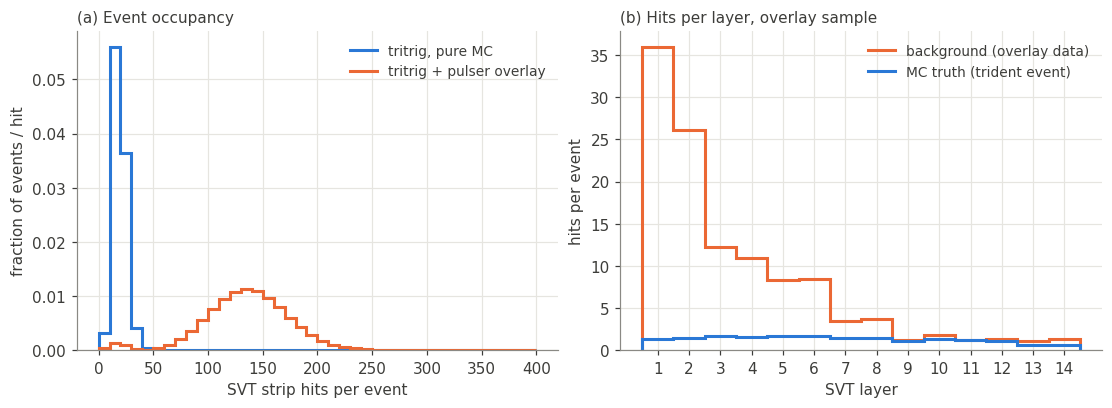

tritrig, pure MC          : mean  19.3 SVT hits / event
tritrig + pulser overlay  : mean 135.6 SVT hits / event


In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
for k in H:
    st.plot_hist(a, H[k]["n_hits"], label=LABEL[k], color=C[k], density=True)
st.style(a, "SVT strip hits per event", "fraction of events / hit", "(a) Event occupancy")

n_ev = H["overlay"]["n_events"].counts[0]
b.stairs(H["overlay"]["layer_bkg"].counts / n_ev, LB, color=C["overlay"], lw=2, label="background (overlay data)")
b.stairs(H["overlay"]["layer_mc"].counts / n_ev, LB, color=C["pure"], lw=2, label="MC truth (trident event)")
b.set_xticks(st.LAYERS)
st.style(b, "SVT layer", "hits per event", "(b) Hits per layer, overlay sample")
plt.show()

for k in H:
    h = H[k]["n_hits"]
    print(f"{LABEL[k]:26s}: mean {np.average(h.centers, weights=h.counts):5.1f} SVT hits / event")

## 2. Tracking efficiency for trident particles (truth view)

The denominator is every trident $e^\pm$ that deposits more than 100 MeV in the ECal.

* **(a) Number of SVT layers hit.** This is the key plot. The efficiency is a step function: below 8 layers the KF
  (almost) never finds the particle in pure MC, at 8 layers it does 75 % of the time, at 9 layers 93 %, and from 10 on
  ≥ 96 %. These steps are the Kalman pattern-recognition hit requirements; §2b shows which hits count. With
  background, particles with 4–7 truth layers are sometimes found, because background hits fill out the track (still
  with purity ≥ 0.5). The price is visible at 9–10 layers, where the overlay efficiency is lower.
* **(c) Dip angle.** Most of the remaining inefficiency is geometric: particles with $|\tan\lambda| \lesssim 0.015$ pass
  through the gap between the top and bottom SVT halves but still reach the ECal. Away from the gap the efficiency is
  99 % (pure) and 98.5 % (overlay); see the table.
* **(b) Momentum.** Efficiency drops below 0.6 GeV, where curling and multiple scattering limit the number of layers
  reached. The overlay costs most between 1.5 and 2.5 GeV, which deserves a closer look.
* **(d) Occupancy.** With this reconstruction and this purity-based matching, the efficiency is **flat** from 50 to
  350 SVT hits per event. This differs from Zhaozhong's strong drop with occupancy (≈ 0.85 → 0.40 at 200 hits for
  the 40 ns window). His efficiency also required the track to be well measured: core of $\Delta p/p$,
  $N_\mathrm{hits} > 8$, $\chi^2 < 20$. The background therefore spoils the *quality* of the tracks it touches far more
  than it prevents finding them, which sections 3 and 4 show directly. (The first overlay bin holds a few percent of
  events whose overlaid pulser event carries almost no SVT data.)

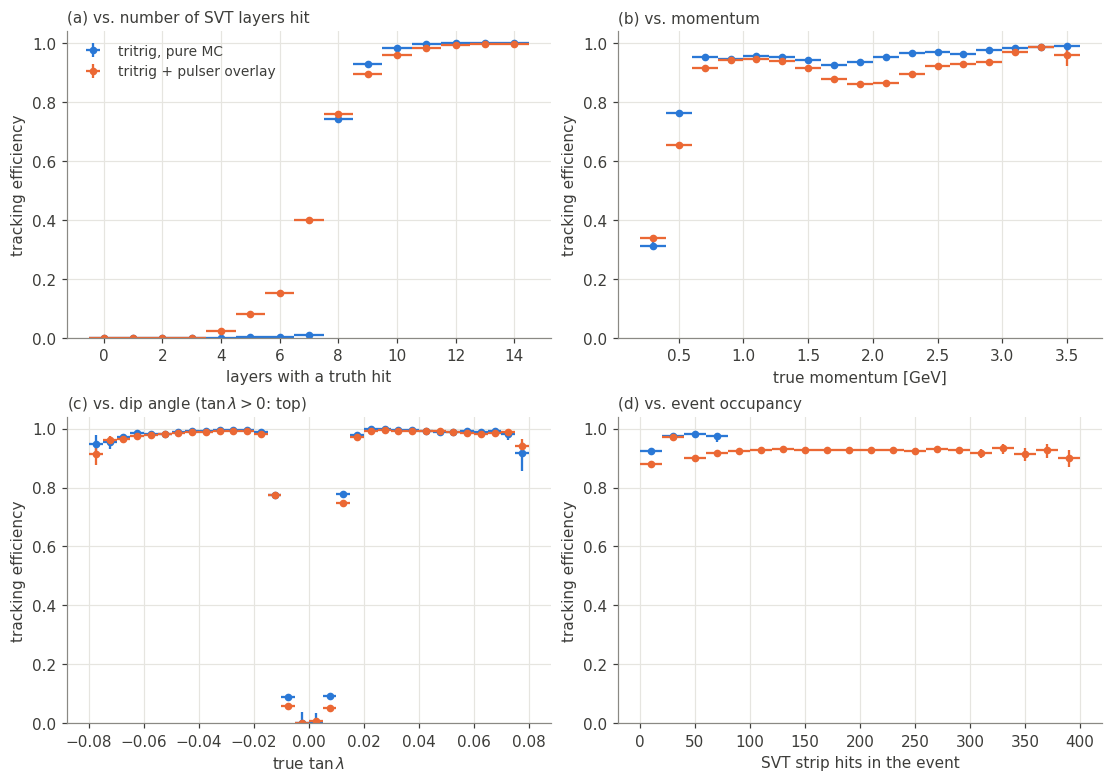

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for k in H:
    kw = dict(label=LABEL[k], color=C[k])
    st.plot_ratio(ax[0, 0], H[k]["eff_layers"], min_total=20, **kw)
    st.plot_ratio(ax[0, 1], H[k]["eff_p"], min_total=20, **kw)
    st.plot_ratio(ax[1, 0], H[k]["eff_tanl"], min_total=20, **kw)
    st.plot_ratio(ax[1, 1], H[k]["eff_occ"], min_total=50, **kw)

st.style(ax[0, 0], "layers with a truth hit", "tracking efficiency", "(a) vs. number of SVT layers hit")
st.style(ax[0, 1], "true momentum [GeV]", "tracking efficiency", "(b) vs. momentum", legend=False)
st.style(ax[1, 0], r"true $\tan\lambda$", "tracking efficiency", r"(c) vs. dip angle ($\tan\lambda>0$: top)", legend=False)
st.style(ax[1, 1], "SVT strip hits in the event", "tracking efficiency", "(d) vs. event occupancy", legend=False)
ax[0, 0].set_xticks(range(0, 15, 2))
for a in ax.flat:
    a.set_ylim(0, 1.04)
plt.show()

In [5]:
def fmt(ratio):
    e, lo, hi = ratio.integral()
    return f"{e:.4f} ± {max(lo, hi):.4f}"

def row(k):
    h = H[k]
    n = h["eff_layers"].total
    return {"particles in acceptance": f"{n.sum():,.0f}",
            "efficiency": fmt(h["eff_p"]),
            "fraction with < 8 layers hit": f"{n[:8].sum() / n.sum():.3f}",
            "efficiency, ≥ 8 layers hit": fmt(h["eff_8plus"]),
            "efficiency, |tanλ| > 0.015": fmt(h["eff_nogap"]),
            "found with > 1 track": f"{h['dup'].integral()[0]:.4f}"}

pd.DataFrame({LABEL[k]: row(k) for k in H}).T

,particles in acceptance,efficiency,fraction with < 8 layers hit,"efficiency, ≥ 8 layers hit","efficiency, |tanλ| > 0.015",found with > 1 track
"tritrig, pure MC","1,184,401",0.9481 ± 0.0002,0.042,0.9895 ± 0.0001,0.9905 ± 0.0001,0.0005
tritrig + pulser overlay,"1,157,926",0.9275 ± 0.0002,0.062,0.9824 ± 0.0001,0.9848 ± 0.0001,0.0213


## 2b. Why the efficiency steps at 8–10 layers: the KF hit requirements

The step in panel (a) above is not a property of the SVT but of the Kalman pattern recognition. The
reconstruction used for both samples
(`PhysicsRun2021MCRecon_KF_WithSpacing_pass5_physics_HitSmear_HitKill_14272.lcsim`, `KalmanParams.java`, identical at
the two hps-java commits used) runs two pattern-recognition iterations and keeps a track only if:

In [6]:
pd.Series(st.KF_REQUIREMENTS, name="requirement").to_frame()

,requirement
min hits (iteration 1 / 2),9 / 8 (top and bottom)
min stereo hits (iteration 1 / 2),4 / 3
min axial hits,2
seed,5 hits from one of 20 fixed module patterns (1...
max hit-time spread on a track,40 ns (maxTimeRange)


**Axial and stereo hits are not interchangeable.** The field is vertical, so tracks bend horizontally. Axial
strips measure *y* (the non-bend coordinate), and only the stereo strips (tilted by 100 mrad in L1–L4, 50 mrad in
L5–L7) measure the bend. Sensor orientation is mirrored between the halves: the stereo layers are the **even** layers
in the top and the **odd** layers in the bottom (`svt::stereo_layers`). The KF requirements are written in terms of
these counts, so the efficiency is shown below as a function of how many *axial* and *stereo* layers the particle
left a hit in (upper row), and of how many of its hits are in the front (L1–L8, modules 1–4) and back (L9–L14,
modules 5–7, hole and slot sensors) of the tracker (lower row). Denominator as in §2: trident e± with > 100 MeV in
the ECal. Cells with fewer than 50 particles are blank.

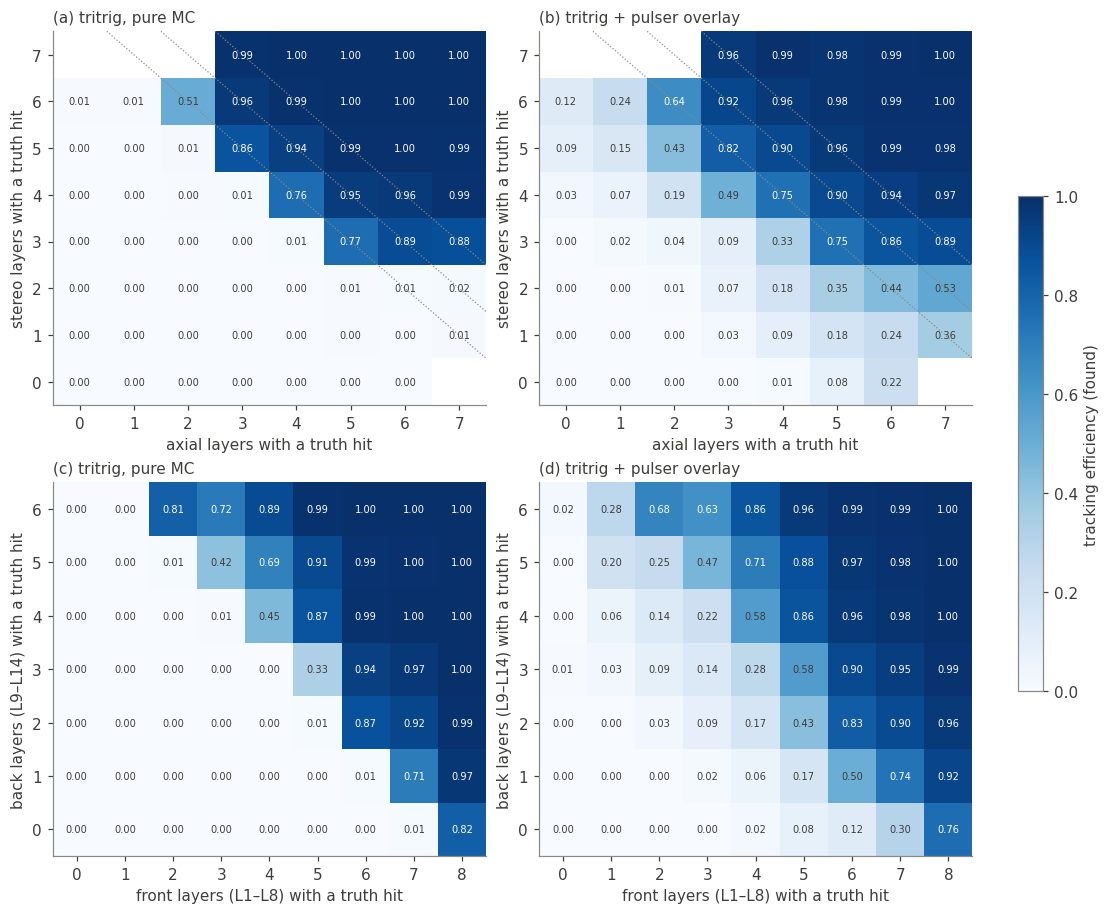

Stereo hits on matched tracks (pure / overlay):


n stereo,0,1,2,3,4,5,6,7
"tritrig, pure MC",0.0,0.0,0.0,0.017,0.119,0.215,0.405,0.245
tritrig + pulser overlay,0.0,0.0,0.0,0.025,0.155,0.225,0.370,0.225


In [7]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8.2))
for col, k in enumerate(H):
    im = st.plot_eff_map(ax[0, col], H[k]["eff_ax_st"], min_total=50)
    ax[0, col].set_xticks(range(0, 8)); ax[0, col].set_yticks(range(0, 8))
    st.style(ax[0, col], "axial layers with a truth hit", "stereo layers with a truth hit",
             f"({'ab'[col]}) {LABEL[k]}", grid=False)
    for n_tot in (8, 9, 10):     # diagonals of constant total number of layers
        ax[0, col].plot([n_tot - 7.5, 7.5], [7.5, n_tot - 7.5], color=C["muted"], lw=0.8, ls=":")
    st.plot_eff_map(ax[1, col], H[k]["eff_fr_bk"], min_total=50)
    ax[1, col].set_xticks(range(0, 9)); ax[1, col].set_yticks(range(0, 7))
    st.style(ax[1, col], "front layers (L1–L8) with a truth hit", "back layers (L9–L14) with a truth hit",
             f"({'cd'[col]}) {LABEL[k]}", grid=False)
fig.colorbar(im, ax=ax, label="tracking efficiency (found)", shrink=0.6)
plt.show()

print("Stereo hits on matched tracks (pure / overlay):")
pd.DataFrame({LABEL[k]: H[k]["n_stereo_trk"].counts / H[k]["n_stereo_trk"].counts.sum() for k in H},
             index=pd.Index(range(0, 8), name="n stereo")).T.round(3)

Dotted diagonals in (a, b) mark 8, 9 and 10 layers in total.

- **The edges of the map are the KF requirements.** In pure MC the efficiency is ≈ 0 with ≤ 2 stereo layers and with
  fewer than 8 layers in total. Every matched track has at least 3 stereo hits (table above). Two axial hits are
  allowed: (2 axial, 6 stereo) is found 51 % of the time.
- **8 layers pass only in the second iteration** (≥ 8 hits, ≥ 3 stereo): 0.76–0.86 for 3–5 stereo layers. With
  9 layers it is 0.89–0.96, and from 10 layers on 0.88–1.
- **Stereo hits count more than axial ones.** The first iteration needs 4 stereo hits, so particles with only 3
  stereo layers saturate at ≈ 0.88–0.89 even with 6–7 axial layers. With 10 layers: 0.88 (3 stereo), 0.96 (4),
  0.99 (5 or more).
- **Where the hits are also matters (c), through the seed patterns.** A seed needs 5 hits in one of the fixed module
  combinations, most of which use both sensors of two adjacent modules.
  - At 8 layers, the splits 8 + 0, 7 + 1, 6 + 2 and 2 + 6 (front + back) are found 71–87 % of the time.
  - The splits 5 + 3, 4 + 4 and 3 + 5 reach only 33–45 %. These are mostly particles with one sensor in each back
    module; for example L3–L7 + L9, L11, L13 is found only 9 % of the time (pure MC).
  - So a missing layer costs more when it breaks a module pair.
- **Background changes the edges, not the plateau (b, d).** Particles with only 0–2 stereo layers, or fewer than
  8 layers, are found from a few % up to ≈ 50 % of the time with the overlay. The KF needs ≥ 3 stereo hits, so these tracks contain
  background hits by construction. A hit filter will lower the "found" efficiency in exactly these cells, but the
  tracks it removes there are the ones with wrong hits. On the plateau (≥ 10 layers, ≥ 4 stereo) the overlay costs
  1–3 %.
- **Consequence for any efficiency comparison:** quote it at fixed (axial, stereo) composition, or for ≥ 10 layers
  with ≥ 4 stereo. Differences between samples or halves in the low cells come from the hit pattern (dead sensors,
  acceptance), not from tracking performance. For example, bottom-half electrons lose the dead L9 stereo sensor; see
  `Tracking_Efficiency_by_Charge_and_Half.ipynb` §4a.

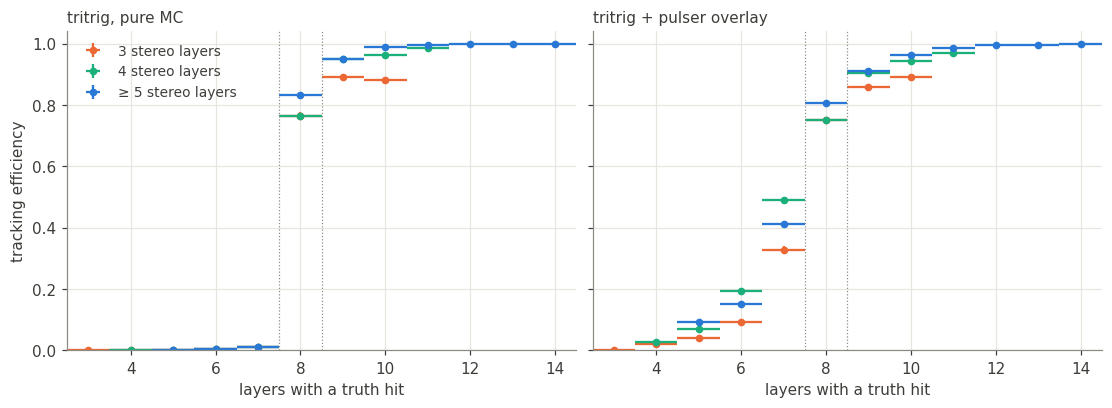

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
stereo_colors = {"3": C["overlay"], "4": C["third"], "≥ 5": C["pure"]}
for a, k in zip(ax, H):
    for s, r in H[k]["eff_lay_st"].items():
        st.plot_ratio(a, r, label=f"{s} stereo layers", color=stereo_colors[s], min_total=50)
    a.axvline(7.5, color=C["muted"], lw=0.8, ls=":"); a.axvline(8.5, color=C["muted"], lw=0.8, ls=":")
    a.set_xlim(2.5, 14.5); a.set_ylim(0, 1.04)
    st.style(a, "layers with a truth hit", "tracking efficiency" if a is ax[0] else None, LABEL[k],
             legend=(a is ax[0]))
plt.show()

Same information as a function of the total number of layers, split by the number of stereo layers. The dotted
lines mark the iteration-2 (8 hits) and iteration-1 (9 hits) thresholds. The step is sharp in pure MC and is
softened by background hits in the overlay. With only 3 stereo layers the efficiency saturates near 0.9, because
such particles can only be found in the second iteration.

## 3. Which tracks are real? (track view)

Every reconstructed track is now classified. A track is *matched* if a trident particle is its majority truth
with purity ≥ 0.5. The other tracks are built from background hits. They can be real beam-background particles
recorded in the pulser data, or random combinations of hits. This is the quantity behind Zhaozhong's track–cluster
matching efficiency versus $N_\mathrm{hits}$ and the last layer.

* In pure MC every track is real, whatever its hit count.
* With background only **half of all tracks are trident particles**, and 41 % contain no MC hit at all. Most of these
  are out of time: requiring the track time to be within ±6 ns of the signal time keeps 93 % of the matched tracks
  and raises the matched fraction to 85 % (table below the figure). These are most likely real beam particles in the
  pulser data, not fakes.
* The matched fraction rises steeply with the number of hits (a) and with the last layer (b). For in-time tracks it
  goes from ≈ 0.5 at ≤ 8 hits to 0.98 at 14 hits.
* The 2D map (c) shows that the two variables are not interchangeable. The best tracks lie on the diagonal, where
  $N_\mathrm{hits}$ equals the last layer: they start in L1 and have no gaps. Along the top row (last layer 14), every
  missing hit costs about 5–8 points of purity. A cut in this plane, rather than on $N_\mathrm{hits}$ alone, is what
  Zhaozhong proposed.
* Background hits on short tracks also damage the momentum measurement (d). Matched tracks with 8–10 hits have 2–3
  times worse resolution with the overlay than without it. With 12–14 hits the resolution is the same (≈ 2.5 %).

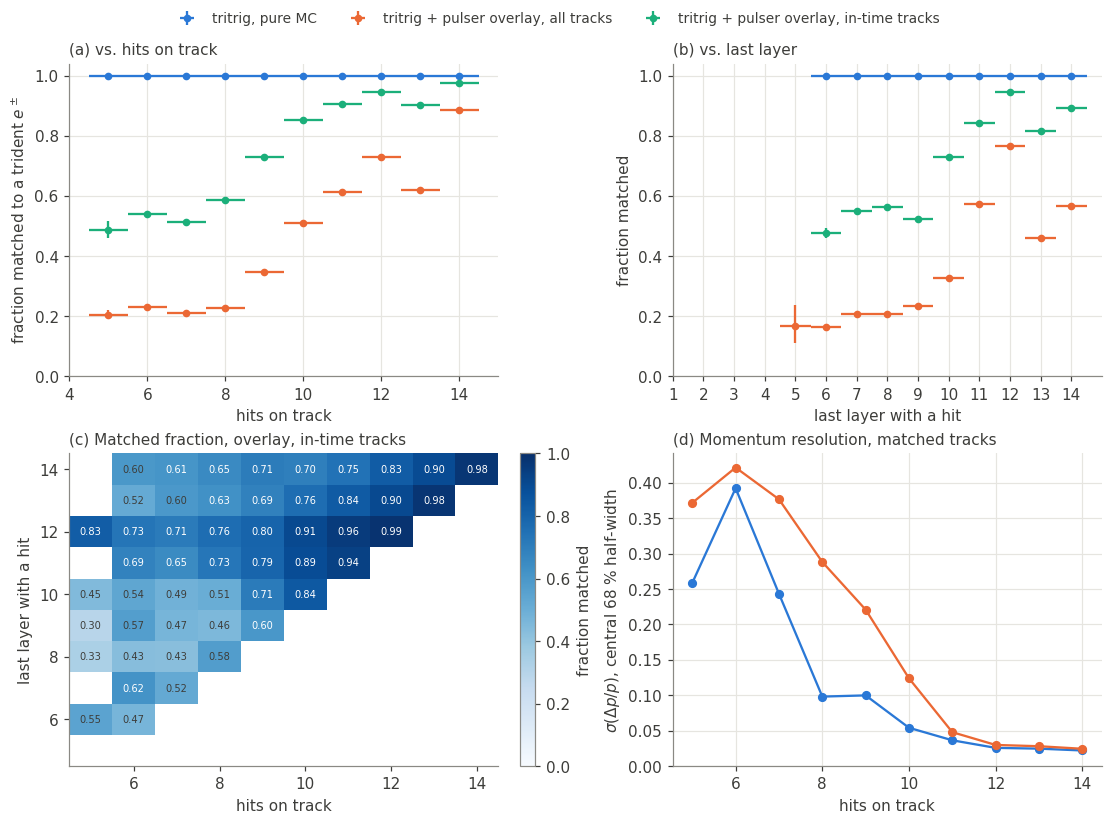

,tracks / event,matched to trident e±,no MC hit at all,in time (|t| < 6 ns),matched tracks in time,"matched, of in-time tracks"
"tritrig, pure MC",1.35,1.000,0.000,0.986,0.986,1.000
tritrig + pulser overlay,2.62,0.509,0.415,0.558,0.931,0.850


In [9]:
fig = plt.figure(figsize=(10, 7.4))
gs = fig.add_gridspec(2, 2)
a, b, c = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 0])
d = fig.add_subplot(gs[1, 1])
curves = [("pure", "trk_nhits", "trk_last", LABEL["pure"], C["pure"]),
          ("overlay", "trk_nhits", "trk_last", LABEL["overlay"] + ", all tracks", C["overlay"]),
          ("overlay", "trk_nhits_t", "trk_last_t", LABEL["overlay"] + ", in-time tracks", C["third"])]
for k, hn, hl, lab, col in curves:
    st.plot_ratio(a, H[k][hn], label=lab, color=col, min_total=20)
    st.plot_ratio(b, H[k][hl], label=lab, color=col, min_total=20)
st.style(a, "hits on track", "fraction matched to a trident $e^\\pm$", "(a) vs. hits on track", legend=False)
fig.legend(*a.get_legend_handles_labels(), loc="outside upper center", ncol=3, frameon=False)
st.style(b, "last layer with a hit", "fraction matched", "(b) vs. last layer", legend=False)
b.set_xticks(st.LAYERS)
for x in (a, b):
    x.set_ylim(0, 1.04)

im = st.plot_eff_map(c, H["overlay"]["trk_map"], min_total=20)
fig.colorbar(im, ax=c, label="fraction matched")
c.set_ylim(4.5, 14.5)
st.style(c, "hits on track", "last layer with a hit", "(c) Matched fraction, overlay, in-time tracks", grid=False)

# (d) momentum resolution of matched tracks vs. hits on track
for k in H:
    med, w = st.central_width(H[k]["dp_nhits"])
    d.plot(st.int_bins(5, 14)[:-1] + 0.5, w, "o-", color=C[k], label=LABEL[k], ms=5, lw=1.5)
st.style(d, "hits on track", r"$\sigma(\Delta p/p)$, central 68 % half-width", "(d) Momentum resolution, matched tracks", legend=False)
d.set_ylim(bottom=0)
plt.show()

def composition(k):
    h = H[k]
    return {"tracks / event": f"{h['trk_no_mc'].total.sum() / h['n_events'].counts[0]:.2f}",
            "matched to trident e±": f"{h['trk_nhits'].integral()[0]:.3f}",
            "no MC hit at all": f"{h['trk_no_mc'].integral()[0]:.3f}",
            "in time (|t| < 6 ns)": f"{h['trk_intime'].integral()[0]:.3f}",
            "matched tracks in time": f"{h['trk_m_intime'].integral()[0]:.3f}",
            "matched, of in-time tracks": f"{h['trk_t_match'].integral()[0]:.3f}"}

pd.DataFrame({LABEL[k]: composition(k) for k in H}).T

## 4. Where tracks lose hits and pick up wrong ones

For each found trident particle, panel (a) gives, per layer, the fraction of its truth hits that are not on its
track (Zhaozhong's "missing-layer fraction", disagreement / truth). Panel (b) gives the fraction of hits on
matched tracks that belong to a different particle or to the background ("wrong-layer fraction",
disagreement / recon).

* **Wrong hits are a background effect in the inner layers.** With the overlay, 23 % of the L1 hits and 20 % of the
  L2 hits on matched tracks are wrong. That falls to ≈ 8 % in L3–L4, 4.5 % in L5–L6, 3 % in L7–L8, and below 1 %
  from L9 on, following the background occupancy of section 1. In pure MC the wrong-hit fraction is below 0.6 %
  everywhere.
* **In L1–L8 the missing fraction is about equal to the wrong fraction.** When the track takes a background hit, it is
  in place of the particle's own hit. This is the case hit filtering can fix.
* **Missing hits in the outer layers are not caused by background.** Even in pure MC 6–9 % of truth hits in L11–L14
  are not on the track. The overlay adds only a few points there. This is the same rise at L13–L14 that Zhaozhong
  reported. Candidate causes are hole/slot sensor overlaps and outlier rejection at the end of the track, but that
  needs a separate study.
* The fractions with the overlay are larger than Zhaozhong's 40 ns numbers (3 % missing, 8.6 % wrong in L1). The
  samples, background overlay and reconstruction version all differ, so only the shape should be compared.

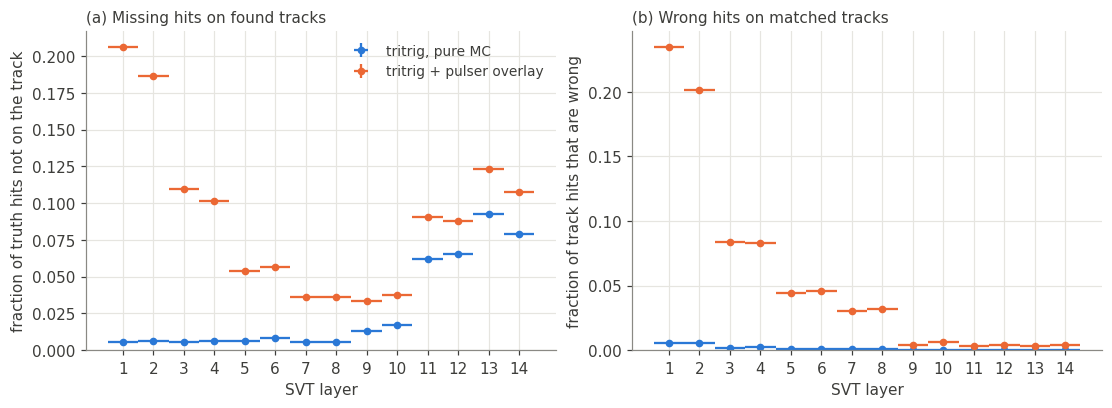

layer,1,2,3,4,5,6,7,8,9,10,11,12,13,14
missing (pure),0.0054,0.0063,0.0056,0.0064,0.0062,0.0081,0.0053,0.0055,0.0129,0.0169,0.0620,0.0656,0.0929,0.0793
missing (overlay),0.2063,0.1864,0.1098,0.1016,0.0536,0.0568,0.0361,0.0359,0.0336,0.0375,0.0907,0.0876,0.1233,0.1073
wrong (pure),0.0058,0.0053,0.0020,0.0022,0.0009,0.0010,0.0010,0.0011,0.0004,0.0005,0.0004,0.0004,0.0004,0.0003
wrong (overlay),0.2347,0.2014,0.0839,0.0829,0.0442,0.0460,0.0302,0.0321,0.0042,0.0061,0.0036,0.0036,0.0033,0.0039


In [10]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
for k in H:
    st.plot_ratio(a, H[k]["missing"], label=LABEL[k], color=C[k], min_total=100)
    st.plot_ratio(b, H[k]["wrong"], label=LABEL[k], color=C[k], min_total=100)
st.style(a, "SVT layer", "fraction of truth hits not on the track", "(a) Missing hits on found tracks")
st.style(b, "SVT layer", "fraction of track hits that are wrong", "(b) Wrong hits on matched tracks", legend=False)
for x in (a, b):
    x.set_xticks(st.LAYERS); x.set_ylim(bottom=0)
plt.show()

pd.DataFrame({f"{what} ({k})": np.round(H[k][what].eff, 4) for what in ("missing", "wrong") for k in H},
             index=pd.Index(st.LAYERS, name="layer")).T

## 5. Toward hit filtering: hit times

Because the background hits come from real data and carry no MC truth, the overlay sample labels every hit as
signal or background. That makes it the natural testbed for hit filters.

* **(a)** Signal hits form a narrow peak (central 68 % within about ±3.5 ns). Background hits are spread almost
  uniformly over the ±75 ns readout window.
* **(b)** The same holds for hits *on* matched tracks, measured relative to the track time. The particle's own hits
  peak sharply, while wrong hits are spread over the whole ±40 ns allowed by the KF. Most wrong hits are therefore
  out of time and could be removed before pattern recognition.
* **(c)** The basic trade-off of a hit-time filter is to keep only hits within ±Δt of the signal time.
  A ±10 ns window keeps 95.5 % of signal hits and 19 % of background (≈ 117 → 22 background hits per event).
  A ±5 ns window keeps 81 % and 9 %.

This is a cut on individual strip-hit times *before* tracking. It is not the same as the KF `mxTdif` limit on the
time spread of hits on a track, which Zhaozhong varied. Hit times in MC are idealised. Data have a worse hit-time
resolution and a sensor-by-sensor $t_0$ calibration, and the data/MC time disagreement noted in the summary document
must be understood before a window chosen here can be applied to data.

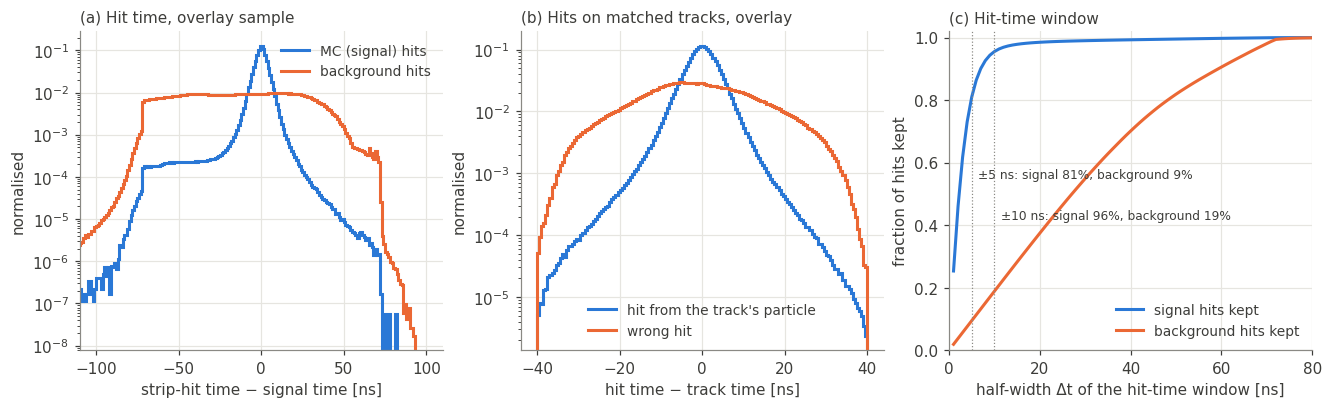

Background hits per event: 117.1; within ±10 ns: 22.1


In [11]:
o = H["overlay"]
widths = np.arange(1, 81)                                       # half-width of the window [ns]
keep_sig = st.window_fraction(o["t_mc"], widths)
keep_bkg = st.window_fraction(o["t_bkg"], widths)

fig, (a, b, c) = plt.subplots(1, 3, figsize=(12, 3.6))
st.plot_hist(a, o["t_mc"], label="MC (signal) hits", color=C["pure"], density=True)
st.plot_hist(a, o["t_bkg"], label="background hits", color=C["overlay"], density=True)
a.set_yscale("log"); a.set_xlim(-110, 110)
st.style(a, "strip-hit time − signal time [ns]", "normalised", "(a) Hit time, overlay sample")

st.plot_hist(b, o["dt_good"], label="hit from the track's particle", color=C["pure"], density=True)
st.plot_hist(b, o["dt_wrong"], label="wrong hit", color=C["overlay"], density=True)
b.set_yscale("log")
st.style(b, "hit time − track time [ns]", "normalised", "(b) Hits on matched tracks, overlay")

c.plot(widths, keep_sig, color=C["pure"], label="signal hits kept")
c.plot(widths, keep_bkg, color=C["overlay"], label="background hits kept")
for w, y in ((5, 0.55), (10, 0.42)):
    c.axvline(w, color=C["muted"], lw=0.8, ls=":")
    c.annotate(f"±{w} ns: signal {keep_sig[w-1]:.0%}, background {keep_bkg[w-1]:.0%}", (w, y),
               xytext=(4, 0), textcoords="offset points", fontsize=8)
c.set_ylim(0, 1.02); c.set_xlim(0, 80)
st.style(c, "half-width Δt of the hit-time window [ns]", "fraction of hits kept", "(c) Hit-time window")
plt.show()

print(f"Background hits per event: {o['t_bkg'].counts.sum() / o['n_events'].counts[0]:.1f}; "
      f"within ±10 ns: {keep_bkg[9] * o['t_bkg'].counts.sum() / o['n_events'].counts[0]:.1f}")

## Summary

| | pure MC | with pulser overlay |
|---|---|---|
| SVT hits / event | 19 | 136 (117 background) |
| efficiency, $e^\pm$ with > 100 MeV in ECal | 0.948 | 0.928 |
| same, outside the beam gap ($|\tan\lambda| > 0.015$) | 0.991 | 0.985 |
| tracks matched to a trident $e^\pm$ (all / in-time) | 1.00 / 1.00 | 0.51 / 0.85 |
| wrong hits on matched tracks, L1 / L2 | 0.6 % / 0.5 % | 23 % / 20 % |

1. **Finding efficiency is governed by the number of SVT layers hit**, with a sharp threshold at 8–10 layers, and by
   the beam gap. The threshold is the KF requirement (≥ 9 hits and ≥ 4 stereo in iteration 1, ≥ 8 and ≥ 3 in
   iteration 2, §2b): the efficiency depends on the number of *stereo* layers, not only on the total. With the current KF it is only weakly affected by background (−0.6 % on the plateau) and does
   not depend on occupancy between 50 and 350 hits per event.
2. **Background mostly damages track quality.** Wrong hits replace correct ones in L1–L4, which degrades the momentum
   resolution of tracks with fewer than 11 hits. In addition, many background tracks (mostly out of time) are
   added.
3. **Track purity is a function of both $N_\mathrm{hits}$ and the last layer.** The diagonal of the
   ($N_\mathrm{hits}$, last-layer) plane, i.e. no gaps, is where real tracks live. This confirms Zhaozhong's
   observation and makes a 2D track-quality cut the natural replacement for $N_\mathrm{hits} \ge 10$.
4. **Hit times separate signal from background well in MC.** A ±10 ns window around the signal time removes 81 % of
   background hits and keeps 95.5 % of signal hits.
5. **Missing hits in L11–L14 (6–9 %) are present even without background** and need a separate explanation.

## Next steps toward hit filtering

* **Quantify the gain without re-running tracking.** For each wrong hit on a matched track, check whether a
  pre-tracking time window would have removed it. Then estimate the corresponding loss of correct hits, per layer.
* **Make the window layer-dependent.** Background is concentrated in L1–L4, so a tight window there and a loose one in
  L9–L14 may keep nearly all signal hits while removing most of the background. The per-layer time resolution
  should be measured from the MC truth.
* **Add other hit information.** Cluster charge and amplitude, and the number of strips, are not stored in these
  MiniDSTs (`use_svt_raw_hits` is off). Remaking a subset with raw hits would allow a multivariate hit classifier.
* **Validate in data.** Compare hit-time distributions of on-track hits in FEE data with MC, layer by layer, before
  choosing a working point.
* **Test in reconstruction.** The `readout/` and `recon/` LCIO files of both samples are kept, so the chosen filter can
  be applied in hps-java and the efficiency, purity and resolution of this notebook can be recomputed directly.